Executing on device: cuda
Total tokens after cleaning: 122,825
Train samples: 98,244 | Val samples: 12,280 | Test samples: 12,281

==================== Training SimpleRNN ====================
[SimpleRNN] Epoch 1/8 -> Train Loss: 5.7175 | Val Loss: 5.1231
[SimpleRNN] Epoch 2/8 -> Train Loss: 4.9055 | Val Loss: 4.9837
[SimpleRNN] Epoch 3/8 -> Train Loss: 4.5353 | Val Loss: 4.9746
[SimpleRNN] Epoch 4/8 -> Train Loss: 4.2471 | Val Loss: 4.9580
[SimpleRNN] Epoch 5/8 -> Train Loss: 4.0172 | Val Loss: 4.9999
[SimpleRNN] Epoch 6/8 -> Train Loss: 3.8164 | Val Loss: 5.0465
[SimpleRNN] Epoch 7/8 -> Train Loss: 3.6509 | Val Loss: 5.1091
[SimpleRNN] Epoch 8/8 -> Train Loss: 3.5086 | Val Loss: 5.1428

==================== Training BiRNN ====================
[BiRNN] Epoch 1/8 -> Train Loss: 5.6480 | Val Loss: 5.1372
[BiRNN] Epoch 2/8 -> Train Loss: 4.8328 | Val Loss: 5.0428
[BiRNN] Epoch 3/8 -> Train Loss: 4.4181 | Val Loss: 5.0722
[BiRNN] Epoch 4/8 -> Train Loss: 4.1069 | Val Loss: 5.1280
[BiRNN] Ep

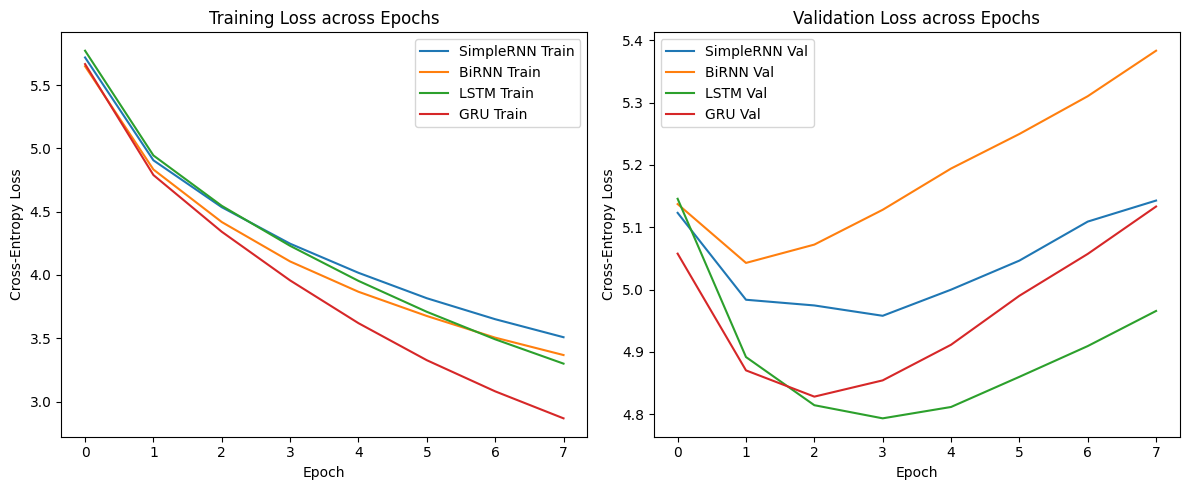


TASK III: SAMPLING TEMPERATURE EVALUATION & GENERATED TEXT

>>> Model: SimpleRNN
  --- Temperature: 0.5 ---
  Seed 1: it was a cold and rainy night in london . but there is a little souvenir of your successes , mr . holmes , i think that i have heard of the ku klux klan . ” “oh ,
          [Distinct-1: 0.821 | Distinct-2: 1.000 | Repetition: 0.000]
  Seed 2: holmes sat in his chair smoking his pipe and as the clock man who had been plucked from the rack , and the crisp rattle of the window was an accomplice in the grounds and the left of
          [Distinct-1: 0.737 | Distinct-2: 0.973 | Repetition: 0.027]
  Seed 3: the door opened and a tall man entered , and his dislike , with a plunge , intelligent smoke , the sympathetic , cocked back , and the crisp rattle of the opium den , with a barred
          [Distinct-1: 0.632 | Distinct-2: 0.919 | Repetition: 0.081]
  --- Temperature: 1.0 ---
  Seed 1: it was a cold and rainy night in london , so we must guess you . ” i had the risen and 

In [1]:
# ==============================================================================
# ICT4403: Foundations of Generative AI - Assignment 2
# Autoregressive Text Generation: Simple RNN, BiRNN, LSTM, and GRU
# ==============================================================================

import os
import re
import time
import math
import string
import urllib.request
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------------------------
# 0. Global Reproducibility Configuration
# ------------------------------------------------------------------------------
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing on device: {DEVICE}")

# ------------------------------------------------------------------------------
# 1. Dataset Acquisition & Preprocessing (Task i)
# ------------------------------------------------------------------------------
DATA_URL = "https://www.gutenberg.org/ebooks/1661.txt.utf-8"
DATA_PATH = "sherlock_holmes.txt"

if not os.path.exists(DATA_PATH):
    print("Downloading 'The Adventures of Sherlock Holmes' from Project Gutenberg...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw_text = f.read()

# Strip Project Gutenberg boilerplate headers and footers
start_marker = "*** START OF THE PROJECT GUTENBERG EBOOK"
end_marker = "*** END OF THE PROJECT GUTENBERG EBOOK"

start_idx = raw_text.find(start_marker)
if start_idx != -1:
    raw_text = raw_text[raw_text.find("\n", start_idx) + 1:]

end_idx = raw_text.find(end_marker)
if end_idx != -1:
    raw_text = raw_text[:end_idx]

# Tokenization pipeline: lowercased, standard word tokens with punctuation separated
def clean_and_tokenize(text):
    text = text.lower()
    text = re.sub(r"([.,!?;:\'\"–—\(\)])", r" \1 ", text)
    tokens = text.split()
    return tokens

tokens = clean_and_tokenize(raw_text)
print(f"Total tokens after cleaning: {len(tokens):,}")

# Build vocabulary capped at top 7,000 words + <unk> and <pad>
VOCAB_SIZE = 7000
word_counts = Counter(tokens)
most_common = word_counts.most_common(VOCAB_SIZE - 2)

vocab = {"<pad>": 0, "<unk>": 1}
for idx, (word, _) in enumerate(most_common, start=2):
    vocab[word] = idx

inv_vocab = {idx: word for word, idx in vocab.items()}
unk_idx = vocab["<unk>"]

token_indices = [vocab.get(tok, unk_idx) for tok in tokens]

# ------------------------------------------------------------------------------
# 2. Sequence Construction & Split (Task i)
# ------------------------------------------------------------------------------
SEQ_LEN = 20  # Sliding window of 20 input words to predict token 21

X = []
y = []
for i in range(len(token_indices) - SEQ_LEN):
    X.append(token_indices[i : i + SEQ_LEN])
    y.append(token_indices[i + SEQ_LEN])

X = np.array(X, dtype=np.int64)
y = np.array(y, dtype=np.int64)

# 80 / 10 / 10 Chronological train/val/test split
total_samples = len(X)
train_end = int(0.80 * total_samples)
val_end = int(0.90 * total_samples)

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]

print(f"Train samples: {len(X_train):,} | Val samples: {len(X_val):,} | Test samples: {len(X_test):,}")

class TextSeqDataset(Dataset):
    def __init__(self, sequences, targets):
        self.sequences = torch.tensor(sequences, dtype=torch.long)
        self.targets = torch.tensor(targets, dtype=torch.long)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return self.sequences[idx], self.targets[idx]

BATCH_SIZE = 128
train_loader = DataLoader(TextSeqDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TextSeqDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TextSeqDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

# ------------------------------------------------------------------------------
# 3. Model Architecture Implementations (Task ii)
# ------------------------------------------------------------------------------
class AutoregressiveLM(nn.Module):
    def __init__(self, rnn_type, vocab_size, embed_dim, hidden_dim, num_layers=1, dropout=0.2):
        super().__init__()
        self.rnn_type = rnn_type
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout)

        if rnn_type == "SimpleRNN":
            self.rnn = nn.RNN(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True)
            fc_in = hidden_dim
        elif rnn_type == "BiRNN":
            self.rnn = nn.RNN(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True, bidirectional=True)
            fc_in = hidden_dim * 2
        elif rnn_type == "LSTM":
            self.rnn = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True)
            fc_in = hidden_dim
        elif rnn_type == "GRU":
            self.rnn = nn.GRU(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True)
            fc_in = hidden_dim
        else:
            raise ValueError(f"Unsupported model type: {rnn_type}")

        self.fc = nn.Linear(fc_in, vocab_size)

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        out, _ = self.rnn(embedded)
        # Use final time step hidden state for next-token prediction
        last_step_out = out[:, -1, :]
        logits = self.fc(last_step_out)
        return logits

# ------------------------------------------------------------------------------
# 4. Training and Evaluation Loops (Task ii)
# ------------------------------------------------------------------------------
EMBED_DIM = 128
HIDDEN_DIM = 256
EPOCHS = 8
LR = 0.001
criterion = nn.CrossEntropyLoss()

def train_and_evaluate(model, model_name):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    train_losses, val_losses = [], []
    start_train_time = time.time()

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            running_loss += loss.item() * batch_x.size(0)

        epoch_train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(epoch_train_loss)

        # Validation
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
                outputs = model(batch_x)
                val_loss = criterion(outputs, batch_y)
                running_val_loss += val_loss.item() * batch_x.size(0)

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        val_losses.append(epoch_val_loss)
        print(f"[{model_name}] Epoch {epoch+1}/{EPOCHS} -> Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

    total_training_time = time.time() - start_train_time

    # Test Evaluation
    model.eval()
    test_loss_sum = 0.0
    top1_correct = 0
    top5_correct = 0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            test_loss_sum += loss.item() * batch_x.size(0)

            # Top-1 and Top-5 calculations
            _, top1_preds = outputs.topk(1, dim=1)
            _, top5_preds = outputs.topk(5, dim=1)

            top1_correct += (top1_preds.squeeze(1) == batch_y).sum().item()
            top5_correct += (top5_preds == batch_y.unsqueeze(1)).sum().item()

    test_loss = test_loss_sum / len(test_loader.dataset)
    perplexity = math.exp(test_loss)
    top1_acc = (top1_correct / len(test_loader.dataset)) * 100.0
    top5_acc = (top5_correct / len(test_loader.dataset)) * 100.0
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    results = {
        "model_name": model_name,
        "num_params": num_params,
        "train_time_sec": total_training_time,
        "test_loss": test_loss,
        "perplexity": perplexity,
        "top1_acc": top1_acc,
        "top5_acc": top5_acc,
        "train_losses": train_losses,
        "val_losses": val_losses
    }
    return results

# Train all four models
model_types = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]
trained_models = {}
benchmark_results = {}

for m_type in model_types:
    print(f"\n==================== Training {m_type} ====================")
    model = AutoregressiveLM(m_type, VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM)
    stats = train_and_evaluate(model, m_type)
    trained_models[m_type] = model
    benchmark_results[m_type] = stats

# Plot Learning Curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
for m_type in model_types:
    plt.plot(benchmark_results[m_type]["train_losses"], label=f"{m_type} Train")
plt.title("Training Loss across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()

plt.subplot(1, 2, 2)
for m_type in model_types:
    plt.plot(benchmark_results[m_type]["val_losses"], label=f"{m_type} Val")
plt.title("Validation Loss across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.tight_layout()
plt.savefig("loss_comparison_curves.png")
plt.show()

# ------------------------------------------------------------------------------
# 5. Text Generation & Temperature Analysis (Task iii)
# ------------------------------------------------------------------------------
def generate_text(model, seed_tokens, gen_length=30, temperature=1.0):
    model.eval()
    curr_indices = [vocab.get(tok.lower(), unk_idx) for tok in seed_tokens]
    generated = list(seed_tokens)

    with torch.no_grad():
        for _ in range(gen_length):
            input_tensor = torch.tensor([curr_indices[-SEQ_LEN:]], dtype=torch.long).to(DEVICE)
            logits = model(input_tensor).squeeze(0)

            # Apply temperature scaling
            scaled_logits = logits / max(temperature, 1e-6)
            probs = torch.softmax(scaled_logits, dim=-1).cpu().numpy()

            # Avoid predicting <pad> or <unk> directly in sampling
            probs[vocab["<pad>"]] = 0.0
            probs[vocab["<unk>"]] = 0.0
            probs = probs / np.sum(probs)

            next_idx = np.random.choice(len(probs), p=probs)
            generated.append(inv_vocab.get(next_idx, "<unk>"))
            curr_indices.append(next_idx)

    return " ".join(generated)

def calculate_metrics(generated_text):
    toks = generated_text.split()
    total = len(toks)
    if total < 2:
        return 0.0, 0.0, 0.0
    bigrams = [tuple(toks[i:i+2]) for i in range(total - 1)]
    distinct_1 = len(set(toks)) / total
    distinct_2 = len(set(bigrams)) / len(bigrams)
    repetition_rate = 1.0 - distinct_2
    return distinct_1, distinct_2, repetition_rate

# Evaluation Seeds
seed_prompts = [
    ["it", "was", "a", "cold", "and", "rainy", "night", "in", "london"],
    ["holmes", "sat", "in", "his", "chair", "smoking", "his", "pipe"],
    ["the", "door", "opened", "and", "a", "tall", "man", "entered"]
]
temperatures = [0.5, 1.0, 1.5]

print("\n" + "="*80)
print("TASK III: SAMPLING TEMPERATURE EVALUATION & GENERATED TEXT")
print("="*80)

generation_records = []

for m_type in model_types:
    print(f"\n>>> Model: {m_type}")
    for temp in temperatures:
        print(f"  --- Temperature: {temp} ---")
        for p_idx, prompt in enumerate(seed_prompts):
            sample = generate_text(trained_models[m_type], prompt, gen_length=30, temperature=temp)
            d1, d2, rep = calculate_metrics(sample)
            generation_records.append({
                "model": m_type, "temp": temp, "prompt_id": p_idx + 1,
                "text": sample, "d1": d1, "d2": d2, "rep": rep
            })
            print(f"  Seed {p_idx+1}: {sample}")
            print(f"          [Distinct-1: {d1:.3f} | Distinct-2: {d2:.3f} | Repetition: {rep:.3f}]")